In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../data/raw/data.csv', sep = ';')
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:
df.columns.tolist()

['Marital status',
 'Application mode',
 'Application order',
 'Course',
 'Daytime/evening attendance\t',
 'Previous qualification',
 'Previous qualification (grade)',
 'Nacionality',
 "Mother's qualification",
 "Father's qualification",
 "Mother's occupation",
 "Father's occupation",
 'Admission grade',
 'Displaced',
 'Educational special needs',
 'Debtor',
 'Tuition fees up to date',
 'Gender',
 'Scholarship holder',
 'Age at enrollment',
 'International',
 'Curricular units 1st sem (credited)',
 'Curricular units 1st sem (enrolled)',
 'Curricular units 1st sem (evaluations)',
 'Curricular units 1st sem (approved)',
 'Curricular units 1st sem (grade)',
 'Curricular units 1st sem (without evaluations)',
 'Curricular units 2nd sem (credited)',
 'Curricular units 2nd sem (enrolled)',
 'Curricular units 2nd sem (evaluations)',
 'Curricular units 2nd sem (approved)',
 'Curricular units 2nd sem (grade)',
 'Curricular units 2nd sem (without evaluations)',
 'Unemployment rate',
 'Inflation r

In [4]:
df.columns = df.columns.str.strip()

In [5]:
df.shape

(4424, 37)

In [6]:
df.dtypes

Marital status                                      int64
Application mode                                    int64
Application order                                   int64
Course                                              int64
Daytime/evening attendance                          int64
Previous qualification                              int64
Previous qualification (grade)                    float64
Nacionality                                         int64
Mother's qualification                              int64
Father's qualification                              int64
Mother's occupation                                 int64
Father's occupation                                 int64
Admission grade                                   float64
Displaced                                           int64
Educational special needs                           int64
Debtor                                              int64
Tuition fees up to date                             int64
Gender        

In [7]:
df['Target'].value_counts(normalize = True)

Target
Graduate    0.499322
Dropout     0.321203
Enrolled    0.179476
Name: proportion, dtype: float64

|Feature name                                         | When it is known       |
|-----------------------------------------------------|------------------------|
|Marital status                                       |Known at enrollment     |          
|Application mode                                     |Known at enrollment     |          
|Application order                                    |Known at enrollment     |          
|Course                                               |Known at enrollment     |         
|Daytime/evening attendance                           |Known at enrollment     |          
|Previous qualification                               |Known at enrollment     |           
|Previous qualification (grade)                       |Known at enrollment     |        
|Nacionality                                          |Known at enrollment     |         
|Mother's qualification                               |Known at enrollment     |         
|Father's qualification                               |Known at enrollment     |          
|Mother's occupation                                  |Known at enrollment     |            
|Father's occupation                                  |Known at enrollment     |           
|Admission grade                                      |Known at enrollment     |          
|Displaced                                            |Known at enrollment     |           
|Educational special needs                            |Known at enrollment     |            
|Debtor                                               |Known after semester 2  |           
|Tuition fees up to date                              |Known after semester 2  |        
|Gender                                               |Known at enrollment     |            
|Scholarship holder                                   |Known after semester 2  |            
|Age at enrollment                                    |Known at enrollment     |
|International                                        |Known at enrollment     |
|Curricular units 1st sem (credited)                  |Known after semester 1  |
|Curricular units 1st sem (enrolled)                  |Known after semester 1  |
|Curricular units 1st sem (evaluations)               |Known after semester 1  |
|Curricular units 1st sem (approved)                  |Known after semester 1  |
|Curricular units 1st sem (grade)                     |Known after semester 1  |
|Curricular units 1st sem (without evaluations)       |Known after semester 1  |
|Curricular units 2nd sem (credited)                  |Known after semester 2  |
|Curricular units 2nd sem (enrolled)                  |Known after semester 2  |
|Curricular units 2nd sem (evaluations)               |Known after semester 2  |
|Curricular units 2nd sem (grade)                     |Known after semester 2  |
|Curricular units 2nd sem (approved)                  |Known after semester 2  |
|Curricular units 2nd sem (without evaluations)       |Known after semester 2  |
|Unemployment rate                                    |Known at enrollment     |
|Inflation rate                                       |Known at enrollment     |
|GDP                                                  |Known at enrollment     |

In [8]:
categorical_features = [
 'Marital status',
 'Application mode',
 'Application order',
 'Course',
 'Daytime/evening attendance',
 'Previous qualification',
 'Nacionality',
 "Mother's qualification",
 "Father's qualification",
 "Mother's occupation",
 "Father's occupation",
 'Displaced',
 'Educational special needs',
 'Debtor',
 'Tuition fees up to date',
 'Gender',
 'Scholarship holder',
 'International'
 ]


In [9]:
df[categorical_features] = df[categorical_features].astype('category')

In [10]:
numerical_features = list(df.select_dtypes(include= ['int64', 'float64']).columns.values)
numerical_features

['Previous qualification (grade)',
 'Admission grade',
 'Age at enrollment',
 'Curricular units 1st sem (credited)',
 'Curricular units 1st sem (enrolled)',
 'Curricular units 1st sem (evaluations)',
 'Curricular units 1st sem (approved)',
 'Curricular units 1st sem (grade)',
 'Curricular units 1st sem (without evaluations)',
 'Curricular units 2nd sem (credited)',
 'Curricular units 2nd sem (enrolled)',
 'Curricular units 2nd sem (evaluations)',
 'Curricular units 2nd sem (approved)',
 'Curricular units 2nd sem (grade)',
 'Curricular units 2nd sem (without evaluations)',
 'Unemployment rate',
 'Inflation rate',
 'GDP']

Since we try to determine whether a student would drop out or not, the data of students who are still enrolled would not provide us labels to classify. For this reason, I will only keep the students with usable target labels

In [11]:
df_alt = df[(df['Target'] == 'Dropout') | (df['Target'] == 'Graduate')]
df_alt['Target'].value_counts()

Target
Graduate    2209
Dropout     1421
Name: count, dtype: int64

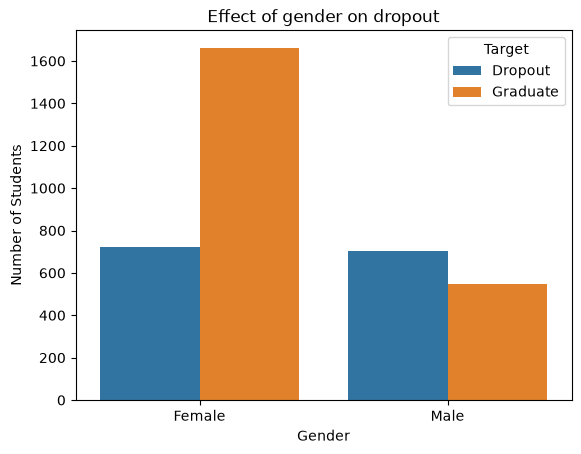

In [12]:
sns.countplot(data = df_alt, x = 'Gender', hue = 'Target')
plt.xlabel('Gender')
plt.xticks([0, 1], ['Female', 'Male'])
plt.ylabel('Number of Students')
plt.title('Effect of gender on dropout')
plt.show()

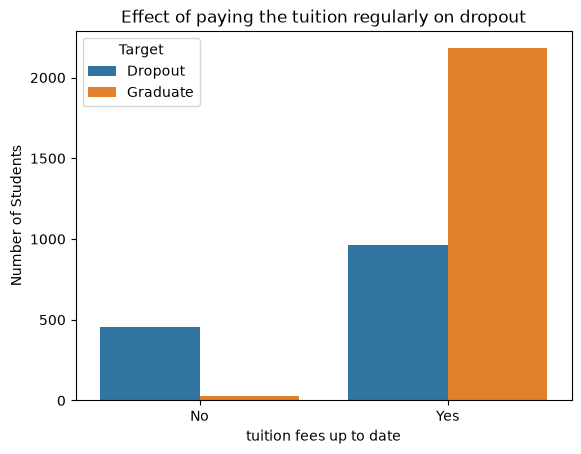

In [18]:
sns.countplot(data = df_alt, x = 'Tuition fees up to date', hue = 'Target')
plt.xlabel('tuition fees up to date')
plt.xticks([0, 1], ['No', 'Yes'])
plt.ylabel('Number of Students')
plt.title('Effect of paying the tuition regularly on dropout')
plt.show()

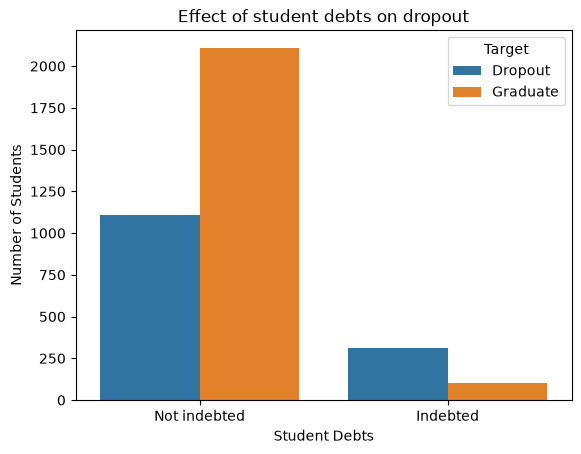

In [14]:
sns.countplot(data = df_alt, x = 'Debtor', hue = 'Target')
plt.xlabel('Student Debts')
plt.xticks([0, 1], ['Not indebted', 'Indebted'])
plt.ylabel('Number of Students')
plt.title('Effect of student debts on dropout')
plt.show()

In [15]:
df_alt.groupby('Debtor')['Target'].value_counts(normalize=True)

Debtor  Target  
0       Graduate    0.655269
        Dropout     0.344731
1       Dropout     0.755448
        Graduate    0.244552
Name: proportion, dtype: float64

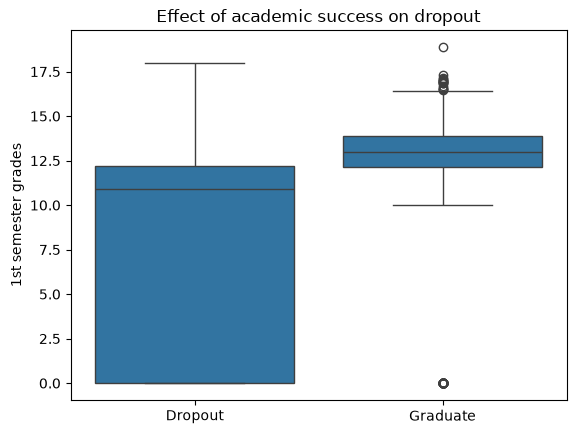

In [16]:
sns.boxplot(data = df_alt, x = 'Target', y = 'Curricular units 1st sem (grade)')
plt.xlabel('')
plt.ylabel('1st semester grades')
plt.title('Effect of academic success on dropout')
plt.show()


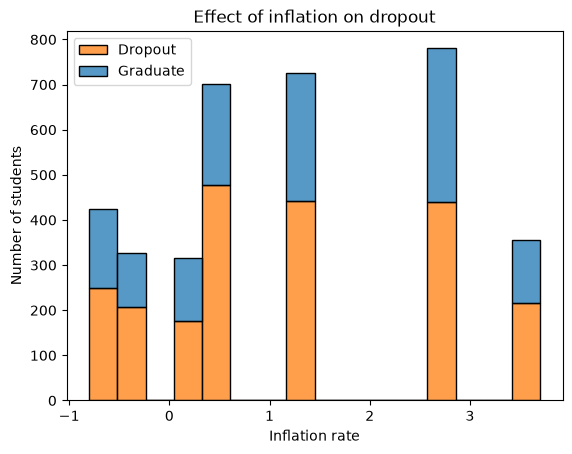

In [17]:
sns.histplot(data = df_alt, x = 'Inflation rate', hue = 'Target',stat = 'count', multiple = 'stack', legend = False)
plt.xlabel('Inflation rate')
plt.ylabel('Number of students')
plt.title('Effect of inflation on dropout')
plt.legend(labels = ['Dropout','Graduate'])
plt.show()


### Findings

- For various models we need to pay attention to when the data  is available through first year. In order to prevent data leakage, we will use features available known at enrollment. We can also develop models for  the end of 1st semester and the end of 2nd semester so that administration could use different models in different timelines.

- I also find out that inflation does not affect dropping out clearly as the graph shows us that ratio of graduate to dropout does not vary meaningfully with inflation through years.

- Male students tend to drop out more.

- Students in debt drop out more (75.5% vs 34.5%).

- Students with lower scores tend to drop out more. On the other hand, zero grades might mean students had already dropped out. We will need to consider that idea while building the model.

- Students who can not keep up with tuition payments tend to drop out.